# Experiments File

This notebook includes experiments. The numbering of the experiments are same as in the report. For further details and analysis please see the report.

## Setup

Common imports, RNG seed, and the baseline Hamiltonian (2D random Heisenberg from the project brief).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
import time

from qml_lib import (
    run_experiment,
    heisenberg_2d_terms,
    enumerate_k_local_paulis,
    make_sparse_observable,
)

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

rng = np.random.default_rng(23)
n_qubits = 10

H_terms = heisenberg_2d_terms(n_rows=5, n_cols=2, rng=rng)
print(f"Hamiltonian: {len(H_terms)} Pauli terms on {n_qubits} qubits")

# Fix the unknown observable for sweeps #1 and #2 (sweep #3 varies it).
feature_strings = enumerate_k_local_paulis(3, n_qubits)
m = len(feature_strings)
_, alpha_true_fixed, obs_idx_fixed, obs_alphas_fixed = (
    make_sparse_observable(feature_strings, n_obs_terms=10, rng=rng))
print(f"Fixed sparse observable: 10 non-zero terms out of m={m}")

Hamiltonian: 39 Pauli terms on 10 qubits
Fixed sparse observable: 10 non-zero terms out of m=3240


## Experiment 1: Time sweep

Vary $t \in \{0.1, 0.5, 1, 2, 5, 10\}$. Crucially, scale `n_trotter` proportionally with $t^2$ to keep Trotter error per unit time constant.

Same $\alpha^*$ across all $t$ so any change in test $R^2$ is attributable to the Hamiltonian dynamics alone.

For results and details please refer to the report.

In [4]:
TS = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
TROTTER_PER_UNIT_T = 10
N_SAMPLES_TIME = 500
N_SHOTS_TIME = 1000

results_time = []
for t in TS:
    n_trot = max(5, int(np.ceil(TROTTER_PER_UNIT_T * t**2)))
    print(f"\n=== t = {t}   (n_trotter = {n_trot}) ===")
    t0 = time.time()
    metrics, _, _, _ = run_experiment(
        H_terms=H_terms,
        n_qubits=n_qubits,
        t=t,
        n_trotter=n_trot,
        k_obs=3,
        n_obs_terms=200,
        n_samples=N_SAMPLES_TIME,
        n_shots=N_SHOTS_TIME,
        obs_idx=obs_idx_fixed,
        obs_alphas=obs_alphas_fixed,
        seed=23,
    )
    metrics["t"] = t
    metrics["n_trotter"] = n_trot
    results_time.append(metrics)
    print(f"  LASSO test R^2  = {metrics['lasso']['test_r2']:+.3f}")
    print(f"  NN-phi test R^2 = {metrics['nn_phi']['test_r2']:+.3f}")
    print(f"  NN-x test R^2   = {metrics['nn_x']['test_r2']:+.3f}")
    print(f"  ({time.time()-t0:.0f}s)")

# Save
with open(RESULTS_DIR / "exp1_time_sweep2.pkl", "wb") as f:
    pickle.dump(results_time, f)
print(f"\nSaved {RESULTS_DIR/'exp1_time_sweep2.pkl'}")


=== t = 0.1   (n_trotter = 5) ===
  LASSO test R^2  = +0.997
  NN-phi test R^2 = +0.217
  NN-x test R^2   = +0.980
  (1868s)

=== t = 0.5   (n_trotter = 5) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.979
  NN-phi test R^2 = +0.683
  NN-x test R^2   = +0.942
  (1726s)

=== t = 1.0   (n_trotter = 10) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.901
  NN-phi test R^2 = +0.583
  NN-x test R^2   = +0.858
  (1762s)

=== t = 2.0   (n_trotter = 40) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.853
  NN-phi test R^2 = +0.652
  NN-x test R^2   = +0.605
  (1935s)

=== t = 5.0   (n_trotter = 250) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.847
  NN-phi test R^2 = +0.185
  NN-x test R^2   = +0.168
  (3188s)

=== t = 10.0   (n_trotter = 1000) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.814
  NN-phi test R^2 = +0.293
  NN-x test R^2   = -0.095
  (7725s)

Saved results\exp1_time_sweep2.pkl


## Experiment 2: Shot Budget Experiment

Vary `n_shots ∈ {50, 100, 500, 1000, 5000}`.

Fixed $t = 2$, fixed Hamiltonian, fixed $\alpha^*$.

Expectation: LASSO test MSE should drop with shot budget toward an $n_\text{shots} = \infty$.

For results and details please refer to the report.

In [ ]:
SHOTS = [50, 100, 500, 1000, 5000]
N_SAMPLES_SHOTS = 500
T_SHOTS = 2.0
N_TROTTER_SHOTS = 20

results_shots = []

# Finite-shot points
for ns in SHOTS:
    print(f"\n=== n_shots = {ns} ===")
    t0 = time.time()
    metrics, _, _, _ = run_experiment(
        H_terms=H_terms,
        n_qubits=n_qubits,
        t=T_SHOTS,
        n_trotter=N_TROTTER_SHOTS,
        k_obs=3,
        n_obs_terms=10,
        n_samples=N_SAMPLES_SHOTS,
        n_shots=ns,
        obs_idx=obs_idx_fixed,
        obs_alphas=obs_alphas_fixed,
        seed=23,
    )
    metrics["n_shots"] = ns
    results_shots.append(metrics)
    print(f"  LASSO test MSE = {metrics['lasso']['test_mse']:.5f}  "
          f"R^2 = {metrics['lasso']['test_r2']:+.3f}")
    print(f"  ({time.time()-t0:.0f}s)")

with open(RESULTS_DIR / "exp2_shot_sweep.pkl", "wb") as f:
    pickle.dump(results_shots, f)
print(f"\nSaved {RESULTS_DIR/'exp2_shot_sweep.pkl'}")

## Experiment 3: Sparsity Sweep

Vary $\|\alpha^*\|_0 \in \{1, 5, 10, 25, 50, 100, 300\}$. Holds the Hamiltonian, time, and shot budget fixed; only the observable changes.

Expectation: at $\|\alpha^*\|_0 = 1$ LASSO should crush the NN. As $\alpha^*$ becomes dense, LASSO's sparsity prior is wrong and the NN catches up.

For results and details please refer to the report.

In [10]:
SPARSITIES = [1, 5, 10, 25, 50, 100, 300]
T_SPARSE = 2.0
N_TROTTER_SPARSE = 20
N_SAMPLES_SPARSE = 500
N_SHOTS_SPARSE = 1000

results_sparsity = []
for i, k0 in enumerate(SPARSITIES):
    print(f"\n=== ||alpha*||_0 = {k0} ===")
    t0 = time.time()
    metrics, _, _, _ = run_experiment(
        H_terms=H_terms,
        n_qubits=n_qubits,
        t=T_SPARSE,
        n_trotter=N_TROTTER_SPARSE,
        k_obs=3,
        n_obs_terms=k0,
        n_samples=N_SAMPLES_SPARSE,
        n_shots=N_SHOTS_SPARSE,
        seed=23 + i,        # fresh α* per point
    )
    metrics["sparsity"] = k0
    results_sparsity.append(metrics)
    print(f"  LASSO test R^2  = {metrics['lasso']['test_r2']:+.3f}  "
          f"(support TP: {metrics['lasso']['support_tp']}/{k0})")
    print(f"  NN-phi test R^2 = {metrics['nn_phi']['test_r2']:+.3f}")
    print(f"  ({time.time()-t0:.0f}s)")

with open(RESULTS_DIR / "exp3_sparsity_sweep.pkl", "wb") as f:
    pickle.dump(results_sparsity, f)
print(f"\nSaved {RESULTS_DIR/'exp3_sparsity_sweep.pkl'}")


=== ||alpha*||_0 = 1 ===
  LASSO test R^2  = -0.001  (support TP: 0/1)
  NN-phi test R^2 = -725128384311017472000.000
  (1760s)

=== ||alpha*||_0 = 5 ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.882  (support TP: 3/5)
  NN-phi test R^2 = +0.554
  (1751s)

=== ||alpha*||_0 = 10 ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.916  (support TP: 2/10)
  NN-phi test R^2 = +0.657
  (1752s)

=== ||alpha*||_0 = 25 ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


... (3 outputs left out)

c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.893  (support TP: 36/100)
  NN-phi test R^2 = +0.606
  (1753s)

=== ||alpha*||_0 = 300 ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  LASSO test R^2  = +0.878  (support TP: 61/300)
  NN-phi test R^2 = +0.529
  (1756s)

Saved results\exp3_sparsity_sweep.pkl


## Experiment 4: Sparsity Sweep 
Vary the locality k of the Pauli feature basis while keeping the truth  at weight-3. k=1,2 should fail catastrophically (truth not in basis); k=3 is the sweet spot; k=4 is over-parameterized.

For results and details please refer to the report.

In [ ]:

from math import comb

K_VALUES        = [1, 2, 3, 4]
T_K             = 2.0
N_TROTTER_K     = 20
N_SAMPLES_K     = 500
N_SHOTS_K       = 1000
N_OBS_TERMS_K   = 10
K_OBSERVABLE    = 3      
N_SEEDS_K       = 2

results_klocal = []
for k_feat in K_VALUES:
    m_k = comb(n_qubits, k_feat) * 3**k_feat
    print(f"\n=== k_feat = {k_feat}   (m = {m_k}) ===")
    for s in range(N_SEEDS_K):
        t0 = time.time()
        metrics, _, _, _ = run_experiment(
            H_terms=H_terms,
            n_qubits=n_qubits,
            t=T_K,
            n_trotter=N_TROTTER_K,
            k_obs=k_feat,
            k_observable=K_OBSERVABLE,
            n_obs_terms=N_OBS_TERMS_K,
            n_samples=N_SAMPLES_K,
            n_shots=N_SHOTS_K,
            seed=300 + s + 10 * K_VALUES.index(k_feat),
        )
        metrics["k_feat"]    = k_feat
        metrics["m"]         = m_k
        metrics["seed"]      = s
        results_klocal.append(metrics)
        in_basis = metrics["lasso"]["obs_terms_in_features"]
        print(f"  seed {s}: LASSO R² = {metrics['lasso']['test_r2']:+.3f}  "
              f"NN-φ R² = {metrics['nn_phi']['test_r2']:+.3f}  "
              f"(α* in basis: {in_basis}/10)  "
              f"({time.time()-t0:.0f}s)")

with open(RESULTS_DIR / "exp5a_klocal_sweep.pkl", "wb") as f:
    pickle.dump(results_klocal, f)
print(f"\nSaved {RESULTS_DIR/'exp5a_klocal_sweep.pkl'}")


=== k_feat = 1   (m = 30) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 0: LASSO R² = +0.022  NN-φ R² = -0.278  (α* in basis: 0/10)  (157s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 1: LASSO R² = -0.033  NN-φ R² = +0.002  (α* in basis: 0/10)  (159s)

=== k_feat = 2   (m = 405) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


... (7 outputs left out)

c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 0: LASSO R² = +0.481  NN-φ R² = +0.271  (α* in basis: 0/10)  (6224s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 1: LASSO R² = +0.740  NN-φ R² = +0.490  (α* in basis: 0/10)  (6242s)

Saved results\exp5a_klocal_sweep.pkl



# Experiment 5: Measurement-basis subsampling
At fixed k=3 feature basis, keep only a random subset of measurement bases.  Models the realistic resource constraint of fewer circuit executions.


In [ ]:


BASIS_SUBSETS   = [50, 100, 300, 600, 1161]  # 1161 = full
T_B             = 2.0
N_TROTTER_B     = 20
N_SAMPLES_B     = 500
N_SHOTS_B       = 1000
N_OBS_TERMS_B   = 10
N_SEEDS_B       = 2

results_basis = []
for k_basis in BASIS_SUBSETS:
    print(f"\n=== basis_subset_size = {k_basis} ===")
    for s in range(N_SEEDS_B):
        t0 = time.time()
        metrics, _, _, _ = run_experiment(
            H_terms=H_terms,
            n_qubits=n_qubits,
            t=T_B,
            n_trotter=N_TROTTER_B,
            k_obs=3,
            basis_subset_size=k_basis,
            n_obs_terms=N_OBS_TERMS_B,
            n_samples=N_SAMPLES_B,
            n_shots=N_SHOTS_B,
            seed=400 + s + 10 * BASIS_SUBSETS.index(k_basis),
        )
        metrics["basis_subset"]  = k_basis
        metrics["m"]             = metrics["m"]
        metrics["seed"]          = s
        results_basis.append(metrics)
        in_basis = metrics["lasso"]["obs_terms_in_features"]
        print(f"  seed {s}: |features| = {metrics['m']:>5d}  "
              f"LASSO R² = {metrics['lasso']['test_r2']:+.3f}  "
              f"(α* in features: {in_basis}/10)  "
              f"({time.time()-t0:.0f}s)")

with open(RESULTS_DIR / "exp5b_basis_subset_sweep.pkl", "wb") as f:
    pickle.dump(results_basis, f)
print(f"\nSaved {RESULTS_DIR/'exp5b_basis_subset_sweep.pkl'}")


=== basis_subset_size = 50 ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 0: |features| =   183  LASSO R² = +0.841  (α* in features: 10/10)  (184s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 1: |features| =   113  LASSO R² = +0.793  (α* in features: 10/10)  (183s)

=== basis_subset_size = 100 ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


... (11 outputs left out)

c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 0: |features| =  3240  LASSO R² = +0.932  (α* in features: 10/10)  (1626s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 1: |features| =  3240  LASSO R² = +0.913  (α* in features: 10/10)  (1627s)

Saved results\exp5b_basis_subset_sweep.pkl


### Experiment 6: Hamiltonian family comparison (8+ extension)

Repeat the same learning task under several different Hamiltonians — the dynamics U = exp(-iHt) change, but the unknown observable, evolution time, Trotter step count, sample size, and shot budget are all held fixed. This isolates how the choice of Hamiltonian alone affects how learnable the resulting expectation values are.

For results and details please refer to the report.

In [ ]:

from qml_lib import (
    heisenberg_2d_terms, heisenberg_1d_terms,
    tfim_terms, mixed_field_ising_terms,
)

ham_rng = np.random.default_rng(42)
HAMILTONIANS = {
    "TFIM (h_z=0)":         tfim_terms(n_qubits, J=1.0, h_x=1.0),
    "1D Heisenberg":        heisenberg_1d_terms(n_qubits, ham_rng),
    "Mixed-field Ising":    mixed_field_ising_terms(n_qubits, J=1.0, h_x=1.0, h_z=0.5),
    "2D Heisenberg (5x2)":  heisenberg_2d_terms(5, 2, ham_rng),
}

T_FAM           = 2.0
N_TROTTER_FAM   = 30
N_SAMPLES_FAM   = 500
N_SHOTS_FAM     = 1000
N_OBS_TERMS_FAM = 10
N_SEEDS_FAM     = 3

results_family = []
for name, H_terms_fam in HAMILTONIANS.items():
    H_norm = np.sum(np.abs([c for c, _ in H_terms_fam]))
    print(f"\n=== {name}  ({len(H_terms_fam)} terms, ||H||_1 = {H_norm:.2f}) ===")

    for s in range(N_SEEDS_FAM):
        t0 = time.time()
        metrics, _, _, _ = run_experiment(
            H_terms=H_terms_fam,
            n_qubits=n_qubits,
            t=T_FAM,
            n_trotter=N_TROTTER_FAM,
            k_obs=3,
            n_obs_terms=N_OBS_TERMS_FAM,
            n_samples=N_SAMPLES_FAM,
            n_shots=N_SHOTS_FAM,
            seed=100 + s,   # fresh α* per seed; Hamiltonian fixed above
        )
        metrics["family"]  = name
        metrics["seed"]    = s
        metrics["H_norm"]  = float(H_norm)
        metrics["H_terms"] = len(H_terms_fam)
        results_family.append(metrics)
        print(f"  seed {s}: LASSO R² = {metrics['lasso']['test_r2']:+.3f}  "
              f"NN-φ R² = {metrics['nn_phi']['test_r2']:+.3f}  "
              f"NN-x R² = {metrics['nn_x']['test_r2']:+.3f}  "
              f"({time.time()-t0:.0f}s)")

with open(RESULTS_DIR / "exp4_hamiltonian_family.pkl", "wb") as f:
    pickle.dump(results_family, f)
print(f"\nSaved {RESULTS_DIR/'exp4_hamiltonian_family.pkl'}")


=== TFIM (h_z=0)  (19 terms, ||H||_1 = 19.00) ===


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 0: LASSO R² = +0.831  NN-φ R² = +0.736  NN-x R² = +0.788  (1820s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 1: LASSO R² = +0.923  NN-φ R² = +0.683  NN-x R² = +0.770  (1859s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


... (15 outputs left out)

c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 1: LASSO R² = +0.661  NN-φ R² = +0.088  NN-x R² = -0.245  (2440s)


c:\Users\mtaha\miniconda3\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


  seed 2: LASSO R² = +0.829  NN-φ R² = +0.443  NN-x R² = +0.535  (2589s)

Saved results\exp4_hamiltonian_family.pkl


## Plots

Each plot loads from disk so it can be regenerated without re-running the experiments.

In [6]:
MODEL_COLORS = {
    "linear_x": "#888888",
    "nn_x":     "#d95f02",
    "lasso":    "#1b9e77",
    "nn_phi":   "#7570b3",
}
MODEL_LABELS = {
    "linear_x": "Linear on x",
    "nn_x":     "NN on x",
    "lasso":    "LASSO on phi(x)",
    "nn_phi":   "NN on phi(x)",
}

### Plot 1: Test R² and MSE vs evolution time

Two-panel: $R^2$ on the left (higher is better), test MSE on the right (log scale, lower is better). All four models on each panel.

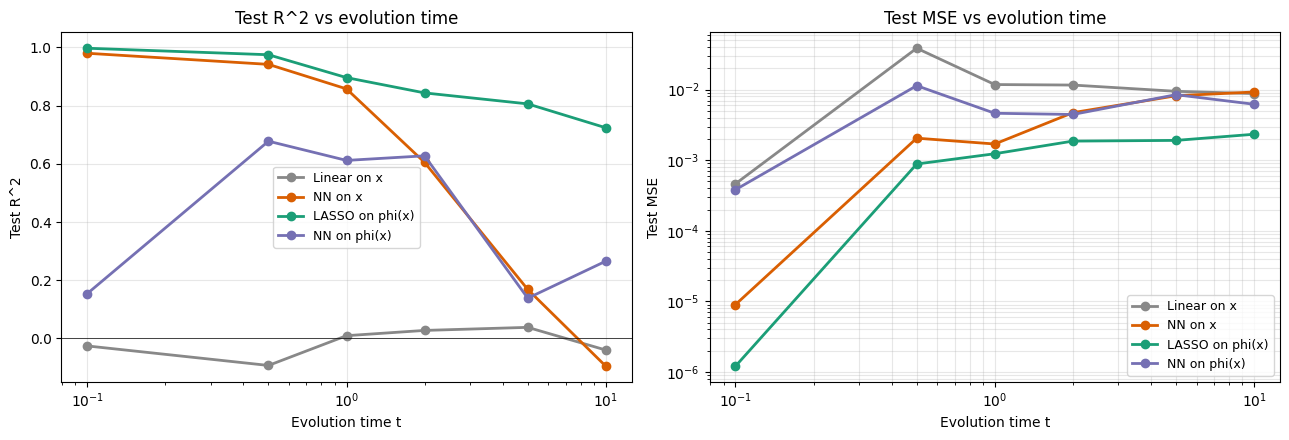

In [ ]:
with open(RESULTS_DIR / "exp1_time_sweep.pkl", "rb") as f:
    results_time = pickle.load(f)

ts = [r["t"] for r in results_time]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for model in MODEL_LABELS:
    r2  = [r[model]["test_r2"]  for r in results_time]
    mse = [r[model]["test_mse"] for r in results_time]
    axes[0].plot(ts, r2,  "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)
    axes[1].plot(ts, mse, "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)

axes[0].set_xlabel("Evolution time t")
axes[0].set_ylabel("Test R^2")
axes[0].set_title("Test R^2 vs evolution time")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].legend(loc="best", fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xscale("log")

axes[1].set_xlabel("Evolution time t")
axes[1].set_ylabel("Test MSE")
axes[1].set_title("Test MSE vs evolution time")
axes[1].set_yscale("log")
axes[1].set_xscale("log")
axes[1].legend(loc="best", fontsize=9)
axes[1].grid(True, alpha=0.3, which="both")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "exp1_time_sweep.png", dpi=150)
plt.show()

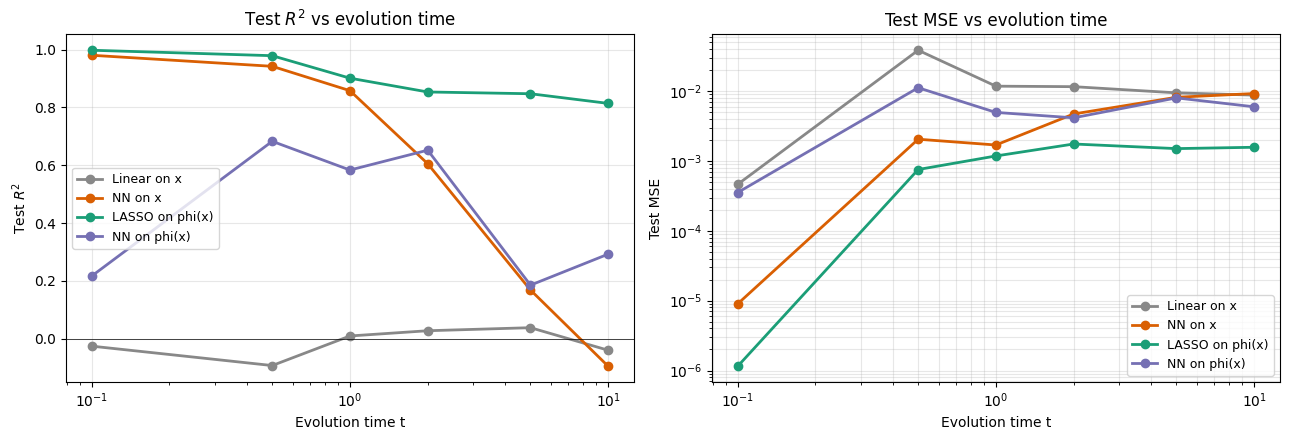

In [13]:
with open(RESULTS_DIR / "exp1_time_sweep2.pkl", "rb") as f:
    results_time = pickle.load(f)

ts = [r["t"] for r in results_time]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for model in MODEL_LABELS:
    r2  = [r[model]["test_r2"]  for r in results_time]
    mse = [r[model]["test_mse"] for r in results_time]
    axes[0].plot(ts, r2,  "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)
    axes[1].plot(ts, mse, "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)

axes[0].set_xlabel("Evolution time t")
axes[0].set_ylabel("Test $R^2$")
axes[0].set_title("Test $R^2$ vs evolution time")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].legend(loc="best", fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xscale("log")

axes[1].set_xlabel("Evolution time t")
axes[1].set_ylabel("Test MSE")
axes[1].set_title("Test MSE vs evolution time")
axes[1].set_yscale("log")
axes[1].set_xscale("log")
axes[1].legend(loc="best", fontsize=9)
axes[1].grid(True, alpha=0.3, which="both")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "time_2.png", dpi=150)
plt.show()

### Plot 2:  Test MSE vs shot budget

Log-log axes. Dashed horizontal lines mark the exact-feature MSEs.

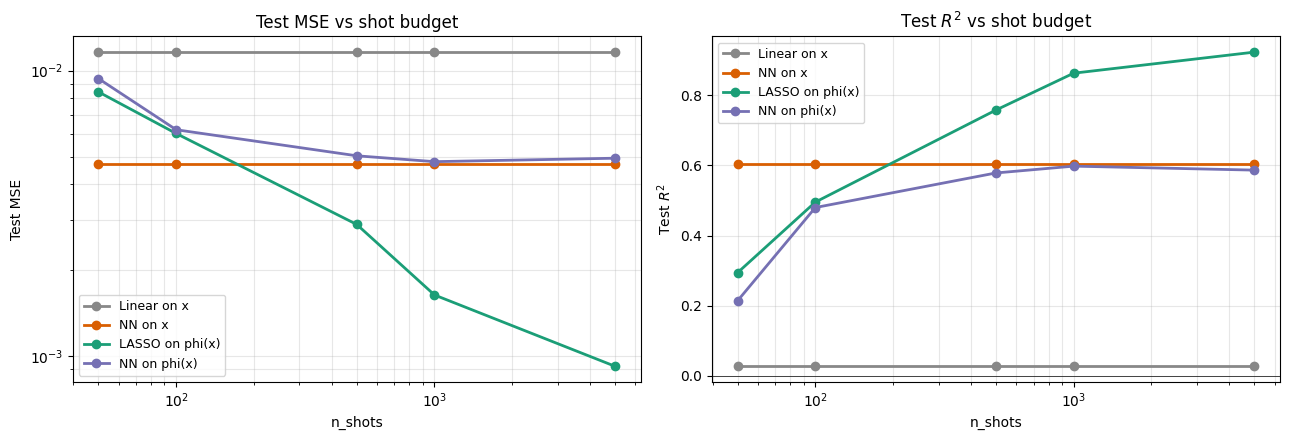

In [ ]:
with open(RESULTS_DIR / "exp2_shot_sweep.pkl", "rb") as f:
    results_shots = pickle.load(f)

finite = [r for r in results_shots if np.isfinite(r["n_shots"])]
exact_list = [r for r in results_shots if not np.isfinite(r["n_shots"])]
exact = exact_list[0] if exact_list else None

shots = [r["n_shots"] for r in finite]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for model in MODEL_LABELS:
    mse_finite = [r[model]["test_mse"] for r in finite]
    r2_finite  = [r[model]["test_r2"]  for r in finite]
    axes[0].plot(shots, mse_finite, "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)
    axes[1].plot(shots, r2_finite, "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)
    if exact is not None:
        axes[0].axhline(exact[model]["test_mse"],
                        color=MODEL_COLORS[model], ls="--", lw=1, alpha=0.6)
        axes[1].axhline(exact[model]["test_r2"],
                        color=MODEL_COLORS[model], ls="--", lw=1, alpha=0.6)


axes[0].set_xlabel("n_shots")
axes[0].set_ylabel("Test MSE")
axes[0].set_title(f"Test MSE vs shot budget")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].legend(loc="best", fontsize=9)
axes[0].grid(True, alpha=0.3, which="both")

axes[1].set_xlabel("n_shots")
axes[1].set_ylabel("Test $R^2$")
axes[1].set_title("Test $R^2$ vs shot budget")
axes[1].set_xscale("log")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].legend(loc="best", fontsize=9)
axes[1].grid(True, alpha=0.3, which="both")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "exp2_shot_sweep.png", dpi=150)
plt.show()

### Plot 3: Test $R^2$ and support recovery vs sparsity

Two-panel. Left: test $R^2$ for the four models. Right: LASSO support recovery.

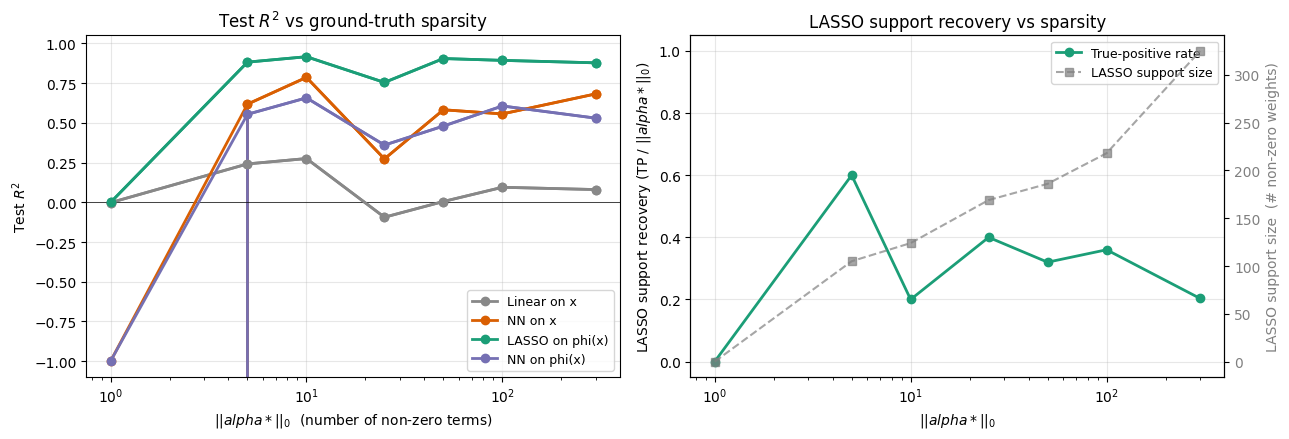

In [15]:
with open(RESULTS_DIR / "exp3_sparsity_sweep.pkl", "rb") as f:
    results_sparsity = pickle.load(f)

ks = [r["sparsity"] for r in results_sparsity]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for model in MODEL_LABELS:
    r2 = [r[model]["test_r2"] for r in results_sparsity]
    axes[0].plot(ks, r2, "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)

axes[0].set_xlabel("$||alpha*||_0$  (number of non-zero terms)")
axes[0].set_ylabel("Test $R^2$")
axes[0].set_title("Test $R^2$ vs ground-truth sparsity")
axes[0].set_xscale("log")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].legend(loc="best", fontsize=9)
axes[0].grid(True, alpha=0.3)

# Support recovery panel
tp = [r["lasso"]["support_tp"] for r in results_sparsity]
support_frac = [t / k for t, k in zip(tp, ks)]
support_size = [r["lasso"]["support_size"] for r in results_sparsity]

ax = axes[1]
ax.plot(ks, support_frac, "o-", color=MODEL_COLORS["lasso"], lw=2,
        label="True-positive rate")
ax.set_xlabel("$||alpha*||_0$")
ax.set_ylabel("LASSO support recovery (TP / $||alpha*||_0$)")
ax.set_title("LASSO support recovery vs sparsity")
ax.set_xscale("log")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, alpha=0.3)


def safe_r2(r2, floor=-1.0):
    """Clip R² for visualization. R² < 0 means 'worse than predicting the mean';
    the exact magnitude isn't meaningful beyond that."""
    return max(r2, floor)

for model in MODEL_LABELS:
    r2 = [safe_r2(r[model]["test_r2"]) for r in results_sparsity]
    axes[0].plot(ks, r2, "o-", color=MODEL_COLORS[model],
                 label=MODEL_LABELS[model], lw=2)

axes[0].set_ylim(-1.1, 1.05)
# Secondary axis: LASSO's chosen support size
ax2 = ax.twinx()
ax2.plot(ks, support_size, "s--", color="gray", lw=1.5, alpha=0.7,
         label="LASSO support size")
ax2.set_ylabel("LASSO support size  (# non-zero weights)",
               color="gray")
ax2.tick_params(axis="y", labelcolor="gray")

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="best", fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "exp3_sparsity_sweep.png", dpi=150)
plt.show()

### Plott 4 - 5: Sparsity Sweep Measurement-basis subsampling

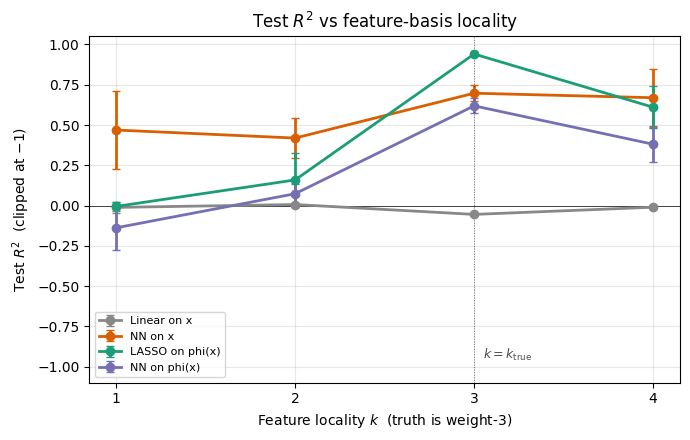

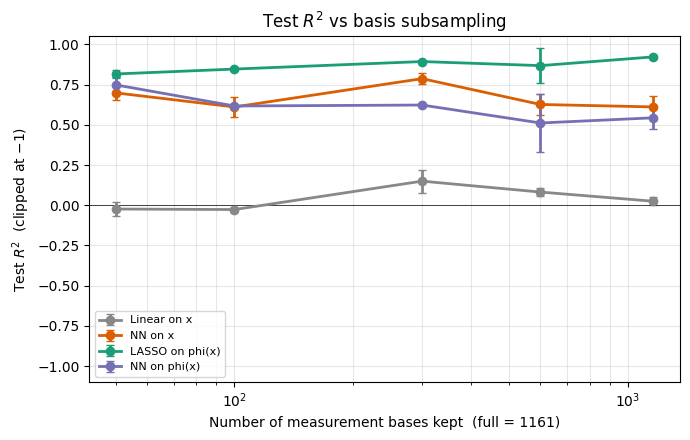


[5A] Test R² vs k (LASSO support coverage):
  k       m     LASSO      NN-φ     α* in basis
  1      30    -0.005    -0.138         0.0/10
  2     405    +0.159    +0.073         0.0/10
  3    3240    +0.941    +0.619        10.0/10
  4   17010    +0.610    +0.381         0.0/10

[5B] Test R² vs basis subsampling:
  |B|  |features|     LASSO    α* found
   50         148    +0.817    10.0/10
  100         261    +0.847    10.0/10
  300         825    +0.894    10.0/10
  600        1696    +0.868    10.0/10
 1161        3240    +0.923    10.0/10


In [ ]:
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

with open(RESULTS_DIR / "exp5a_klocal_sweep.pkl", "rb") as f:
    res_a = pickle.load(f)
with open(RESULTS_DIR / "exp5b_basis_subset_sweep.pkl", "rb") as f:
    res_b = pickle.load(f)

by_k = defaultdict(list)
for r in res_a:
    by_k[r["k_feat"]].append(r)

by_b = defaultdict(list)
for r in res_b:
    by_b[r["basis_subset"]].append(r)

#  Figure 5A: vary k_feat 
fig, ax = plt.subplots(figsize=(7, 4.5))
ks = sorted(by_k.keys())
for model in MODEL_LABELS:
    means, stds = [], []
    for k in ks:
        vals = [max(r[model]["test_r2"], -1.0) for r in by_k[k]]
        means.append(np.mean(vals)); stds.append(np.std(vals))
    ax.errorbar(ks, means, yerr=stds, marker="o",
                color=MODEL_COLORS[model], label=MODEL_LABELS[model],
                lw=2, capsize=3)

ax.axvline(3, color="k", ls=":", lw=0.7, alpha=0.5)
ax.text(3.05, -0.95, r"$k = k_\mathrm{true}$", fontsize=9, alpha=0.7)
ax.set_xlabel(r"Feature locality $k$  (truth is weight-3)")
ax.set_ylabel(r"Test $R^2$  (clipped at $-1$)")
ax.set_title(r"Test $R^2$ vs feature-basis locality")
ax.set_xticks(ks)
ax.set_ylim(-1.1, 1.05)
ax.axhline(0, color="k", lw=0.5)
ax.legend(loc="best", fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "exp5a_klocal.png", dpi=150)
plt.show()

#  Figure 5B: vary basis_subset_size 
fig, ax = plt.subplots(figsize=(7, 4.5))
bs = sorted(by_b.keys())
for model in MODEL_LABELS:
    means, stds = [], []
    for b in bs:
        vals = [max(r[model]["test_r2"], -1.0) for r in by_b[b]]
        means.append(np.mean(vals)); stds.append(np.std(vals))
    ax.errorbar(bs, means, yerr=stds, marker="o",
                color=MODEL_COLORS[model], label=MODEL_LABELS[model],
                lw=2, capsize=3)

ax.set_xlabel(r"Number of measurement bases kept  (full = 1161)")
ax.set_ylabel(r"Test $R^2$  (clipped at $-1$)")
ax.set_title(r"Test $R^2$ vs basis subsampling")
ax.set_xscale("log")
ax.set_ylim(-1.1, 1.05)
ax.axhline(0, color="k", lw=0.5)
ax.legend(loc="best", fontsize=8)
ax.grid(True, alpha=0.3, which="both")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "exp5b_basis_subset.png", dpi=150)
plt.show()

# Print tables
print("\n[5A] Test R² vs k (LASSO support coverage):")
print(f"{'k':>3s}  {'m':>6s}  {'LASSO':>8s}  {'NN-φ':>8s}  {'α* in basis':>14s}")
for k in ks:
    rs = by_k[k]
    in_basis = np.mean([r["lasso"]["obs_terms_in_features"] for r in rs])
    print(f"{k:>3d}  {rs[0]['m']:>6d}  "
          f"{np.mean([r['lasso']['test_r2'] for r in rs]):>+8.3f}  "
          f"{np.mean([r['nn_phi']['test_r2'] for r in rs]):>+8.3f}  "
          f"{in_basis:>10.1f}/10")

print("\n[5B] Test R² vs basis subsampling:")
print(f"{'|B|':>5s}  {'|features|':>10s}  {'LASSO':>8s}  {'α* found':>10s}")
for b in bs:
    rs = by_b[b]
    in_basis = np.mean([r["lasso"]["obs_terms_in_features"] for r in rs])
    feats    = np.mean([r["m"] for r in rs])
    print(f"{b:>5d}  {feats:>10.0f}  "
          f"{np.mean([r['lasso']['test_r2'] for r in rs]):>+8.3f}  "
          f"{in_basis:>6.1f}/10")

### Plot 6: Different Hamiltonian Families


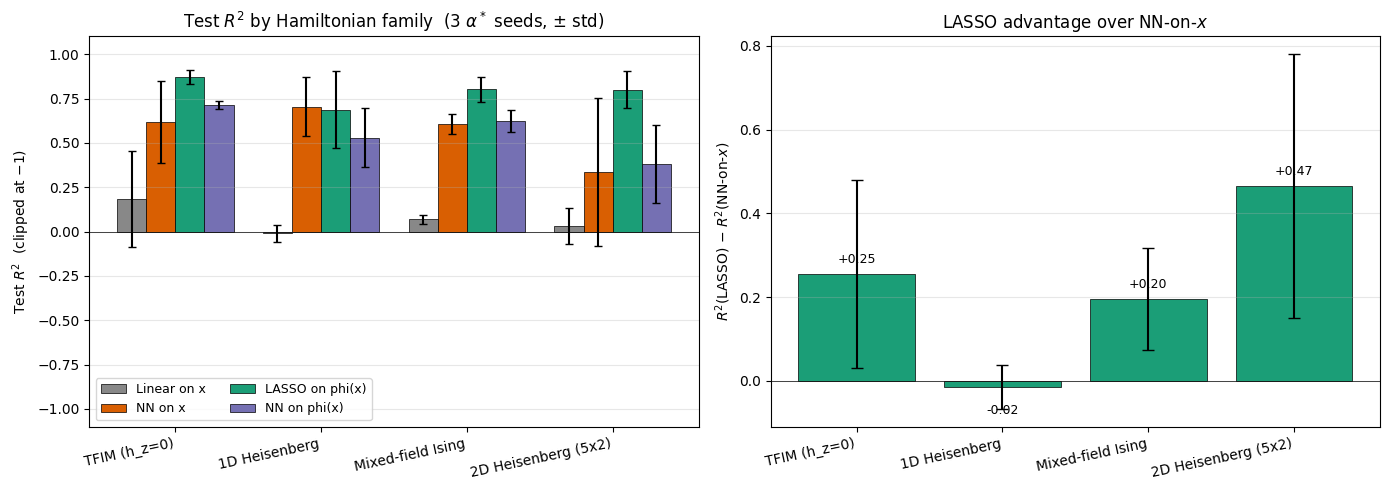


Mean test R² per family (±std across seeds):
Family                            LASSO           NN-φ           NN-x          Lin-x            gap
TFIM (h_z=0)              +0.870±0.039  +0.712±0.022  +0.615±0.231  +0.184±0.270  +0.255±0.225
1D Heisenberg             +0.688±0.218  +0.528±0.167  +0.703±0.166  -0.011±0.048  -0.015±0.052
Mixed-field Ising         +0.801±0.070  +0.623±0.062  +0.606±0.055  +0.069±0.027  +0.195±0.122
2D Heisenberg (5x2)       +0.800±0.103  +0.382±0.219  +0.335±0.417  +0.032±0.102  +0.465±0.315


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

with open(RESULTS_DIR / "exp4_hamiltonian_family.pkl", "rb") as f:
    results_family = pickle.load(f)

by_fam = defaultdict(list)
for r in results_family:
    by_fam[r["family"]].append(r)

try:
    families = [f for f in HAMILTONIANS.keys() if f in by_fam]
except NameError:
    families = list(by_fam.keys())

models = list(MODEL_LABELS.keys())

n_seeds_fam = max(len(by_fam[f]) for f in families)

x     = np.arange(len(families))
width = 0.2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#  Left: test R^2 grouped bar chart, one bar per model per family 
for j, model in enumerate(models):
    means = [np.mean([max(r[model]["test_r2"], -1.0) for r in by_fam[f]])
             for f in families]
    stds  = [np.std([max(r[model]["test_r2"], -1.0) for r in by_fam[f]])
             for f in families]
    axes[0].bar(x + (j - 1.5) * width, means, width,
                yerr=stds, capsize=3,
                color=MODEL_COLORS[model], label=MODEL_LABELS[model],
                edgecolor="black", linewidth=0.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(families, rotation=12, ha="right")
axes[0].set_ylabel(r"Test $R^2$  (clipped at $-1$)")
axes[0].set_title(rf"Test $R^2$ by Hamiltonian family  "
                  rf"({n_seeds_fam} $\alpha^*$ seeds, $\pm$ std)")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].legend(loc="lower left", fontsize=9, ncol=2)
axes[0].grid(True, axis="y", alpha=0.3)
axes[0].set_ylim(-1.1, 1.1)

 
adv_means, adv_stds = [], []
for fam in families:
    advs = [r["lasso"]["test_r2"] - r["nn_x"]["test_r2"] for r in by_fam[fam]]
    adv_means.append(np.mean(advs))
    adv_stds.append(np.std(advs))

bars = axes[1].bar(x, adv_means, yerr=adv_stds, capsize=4,
                   color="#1b9e77", edgecolor="black", linewidth=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(families, rotation=12, ha="right")
axes[1].set_ylabel(r"$R^2$(LASSO) $-$ $R^2$(NN-on-$x$)")
axes[1].set_title(r"LASSO advantage over NN-on-$x$")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].grid(True, axis="y", alpha=0.3)
for b, v in zip(bars, adv_means):
    axes[1].text(b.get_x() + b.get_width() / 2,
                 v + (0.02 if v >= 0 else -0.04),
                 f"{v:+.2f}", ha="center",
                 va="bottom" if v >= 0 else "top", fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "exp4_hamiltonian_family.png", dpi=150)
plt.show()

print("\nMean test R² per family (±std across seeds):")
print(f"{'Family':<24s}  {'LASSO':>13s}  {'NN-φ':>13s}  {'NN-x':>13s}  "
      f"{'Lin-x':>13s}  {'gap':>13s}")
for fam in families:
    rs = by_fam[fam]
    def stat(key):
        vals = [r[key[0]][key[1]] for r in rs]
        return np.mean(vals), np.std(vals)
    lasso_m, lasso_s = stat(("lasso",    "test_r2"))
    nnphi_m, nnphi_s = stat(("nn_phi",   "test_r2"))
    nnx_m, nnx_s     = stat(("nn_x",     "test_r2"))
    lin_m, lin_s     = stat(("linear_x", "test_r2"))
    gaps = [r["lasso"]["test_r2"] - r["nn_x"]["test_r2"] for r in rs]
    gap_m, gap_s = np.mean(gaps), np.std(gaps)
    print(f"{fam:<24s}  "
          f"{lasso_m:>+6.3f}±{lasso_s:.3f}  "
          f"{nnphi_m:>+6.3f}±{nnphi_s:.3f}  "
          f"{nnx_m:>+6.3f}±{nnx_s:.3f}  "
          f"{lin_m:>+6.3f}±{lin_s:.3f}  "
          f"{gap_m:>+6.3f}±{gap_s:.3f}")